# 🛑 TASK 4: Experimental use of association rules with qualitative and quantitative categories by using the apriori algorithm

---

To discover significant patterns in our dataset, we have chosen to employ the Apriori method. This methodology, originally conceived for the analysis of transactions in commercial environments, is also valuable for detecting relationships and associations between variables when the objective is to identify correlations that are not obvious at first glance. In our case, the application of Apriori seeks to unravel links between clinical variables, symptoms or medical conditions, and thus provide information that may be relevant during the triage phase or initial assessment of the patient.

To obtain a clearer view of the relationships between different types of variables, we have decided to separate the analysis into two dimensions: on the one hand, we will address variables of a continuous nature, and on the other, we will work with qualitative variables. This division will allow a clearer interpretation of the interactions, since the dynamics that emerge between numerical data can differ substantially from those observed between nominal categories or qualitative attributes. 

**Reasoning behind this approach:**
While the Apriori method emerged in the context of “shopping basket” analysis in order to identify which products are usually purchased together by consumers, its application to the medical sphere might seem, at first glance, decontextualized or even unethical. From a simplistic perspective, equating symptoms or diagnoses to “products” purchased by a “client-patient” is an analogy that lacks sensitivity and nuance. However, the key lies in reframing the purpose and scope of the technique: instead of “selling” diagnoses or treatments, the idea is to use the logic of Apriori to isolate recurrent patterns of clinical presentation.

By assuming this perspective, medical variables are analyzed as sets of symptoms and associated conditions that occur simultaneously in certain cases. The goal is to extract association rules that can serve as a guide to health professionals. Such rules, supported by robust measures of support, confidence, and elevation, can assist the personal physician during triage by suggesting that the combination of certain symptoms increases the likelihood of an underlying pathology. With this knowledge, the healthcare team can prioritize patients in a more agile and informed manner, optimizing resource allocation and reducing the time required to determine the steps to follow in the diagnostic and treatment process.

Ultimately, the application of Apriori to the clinical field does not pursue a commercial instrumentalization of medical information, but rather seeks to enrich decision-making with data based on empirical evidence, thus improving the efficiency and quality of care provided to patients. In this way, the Apriori method becomes a powerful complementary tool, capable of offering new perspectives and insights to the analysis of medical data, provided that it is applied with an ethical, contextualized vision oriented toward the well-being of the patient.

---

In [1]:
from efficient_apriori import apriori
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
data_apriori = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataCleaned.csv',index_col='ID')
numercial_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv',index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv',index_col='ID')

In [2]:
data_apriori.head()

,age,sex,dzgroup,dzclass,num.co,edu,income,charges,totcst,avtisst,...,crea,sod,ph,bun,urine,adlsc,death,hospdead,sfdm2,Adls_Adlp_merge
ID,,,,,,,,,,,,,,,,,,,,,
0,62.84998,male,Lung Cancer,Cancer,0,11.000000,$11-$25k,9715.0,31100.865401,7.000000,...,1.199951,141.0,7.459961,6.51,2502.0,7.0,0,0,0,7.0
1,60.33899,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.000000,$11-$25k,34496.0,31100.865401,29.000000,...,5.500000,132.0,7.250000,6.51,2502.0,1.0,1,1,<2 mo. follow-up,1.0
2,52.74698,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.000000,under $11k,41094.0,31100.865401,13.000000,...,2.000000,134.0,7.459961,6.51,2502.0,0.0,1,0,<2 mo. follow-up,0.5
3,42.38498,female,Lung Cancer,Cancer,2,11.000000,under $11k,3075.0,31100.865401,7.000000,...,0.799927,139.0,7.415340,6.51,2502.0,0.0,1,0,no(M2 and SIP pres),0.0
4,79.88495,female,ARF/MOSF w/Sepsis,ARF/MOSF,1,11.749662,Unknown,50127.0,31100.865401,18.666656,...,0.799927,143.0,7.509766,6.51,2502.0,2.0,0,0,no(M2 and SIP pres),2.0


## 🛑 Analysis with all quantitative variables

In [3]:
for col in numercial_features.columns:
    # Crear 10 bins y asignar etiquetas con el nombre de la columna
    data_apriori[f'{col}_binned'] = pd.cut(data_apriori[col],
                                           bins=10,
                                           labels=[f'{i+1}' for i in range(10)])
data_apriori=data_apriori.drop(columns=numercial_features.columns)

In [4]:
data_apriori_dummies = pd.get_dummies(data_apriori)
data_apriori_dummies.head()

,diabetes,dementia,death,hospdead,sex_female,sex_male,dzgroup_ARF/MOSF w/Sepsis,dzgroup_CHF,dzgroup_COPD,dzgroup_Cirrhosis,...,Adls_Adlp_merge_binned_1,Adls_Adlp_merge_binned_2,Adls_Adlp_merge_binned_3,Adls_Adlp_merge_binned_4,Adls_Adlp_merge_binned_5,Adls_Adlp_merge_binned_6,Adls_Adlp_merge_binned_7,Adls_Adlp_merge_binned_8,Adls_Adlp_merge_binned_9,Adls_Adlp_merge_binned_10
ID,,,,,,,,,,,,,,,,,,,,,
0,0,0,0,0,False,True,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,0,0,1,1,True,False,False,False,False,True,...,False,True,False,False,False,False,False,False,False,False
2,0,0,1,0,True,False,False,False,False,True,...,True,False,False,False,False,False,False,False,False,False
3,0,0,1,0,True,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
4,0,0,0,0,True,False,True,False,False,False,...,False,False,True,False,False,False,False,False,False,False


In [5]:
# Convertir el DataFrame a formato de transacción
transactions = []

# Iterar por cada fila del DataFrame
for _, row in data_apriori_dummies.iterrows():
    transaction = [col for col, value in row.items() if value is True]
    transactions.append(tuple(transaction))  # Convertir cada transacción a tupla


In [6]:
print("\nLista de transacciones:")
print(transactions)


Lista de transacciones:
[('sex_male', 'dzgroup_Lung Cancer', 'dzclass_Cancer', 'income_$11-$25k', 'race_other', 'ca_metastatic', 'sfdm2_0', 'age_binned_6', 'num.co_binned_1', 'edu_binned_4', 'charges_binned_1', 'totcst_binned_1', 'avtisst_binned_1', 'hday_binned_1', 'meanbp_binned_5', 'wblc_binned_1', 'hrt_binned_3', 'resp_binned_3', 'temp_binned_5', 'pafi_binned_5', 'alb_binned_1', 'bili_binned_1', 'crea_binned_1', 'sod_binned_5', 'ph_binned_7', 'bun_binned_1', 'urine_binned_3', 'adlsc_binned_10', 'Adls_Adlp_merge_binned_10'), ('sex_female', 'dzgroup_Cirrhosis', 'dzclass_COPD/CHF/Cirrhosis', 'income_$11-$25k', 'race_white', 'ca_no', 'sfdm2_<2 mo. follow-up', 'age_binned_6', 'num.co_binned_3', 'edu_binned_4', 'charges_binned_1', 'totcst_binned_1', 'avtisst_binned_4', 'hday_binned_1', 'meanbp_binned_3', 'wblc_binned_1', 'hrt_binned_4', 'resp_binned_4', 'temp_binned_3', 'pafi_binned_1', 'alb_binned_2', 'bili_binned_1', 'crea_binned_3', 'sod_binned_4', 'ph_binned_5', 'bun_binned_1', 'uri

In [7]:
conjuntos, reglas = apriori(transactions,
                            min_support = 0.6,
                            min_confidence = 0.6)

In [8]:
# Filtrando reglas con consecuente de un elemento
reglas = filter(lambda regla: len(regla.rhs) == 1, reglas)

In [9]:
reglas_dfs = []  # Lista para almacenar los DataFrames de cada regla

for regla in reglas:
    # Crear un DataFrame para cada regla
    df_regla = pd.DataFrame({
        'Antecedente': [', '.join(list(regla.lhs))],  # Antecedente
        'Consecuente': [', '.join(list(regla.rhs))],  # Consecuente
        'Support': [regla.support],                    # Soporte
        'Confidence': [regla.confidence],              # Confianza
        'Lift': [regla.lift]                           # Lift
    })

    # Añadir el DataFrame de la regla a la lista
    reglas_dfs.append(df_regla)

# Concatenar todos los DataFrames de las reglas en un solo DataFrame
df_reglas = pd.concat(reglas_dfs, ignore_index=True)


In [10]:
df_reglas.to_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/Apriori Task4/DataModels_reglas.csv',index=True)

### To visualize the association rules in some way, we create a node graph where each node is the consequent that we have found given our criteria.

In [11]:
import networkx as nx

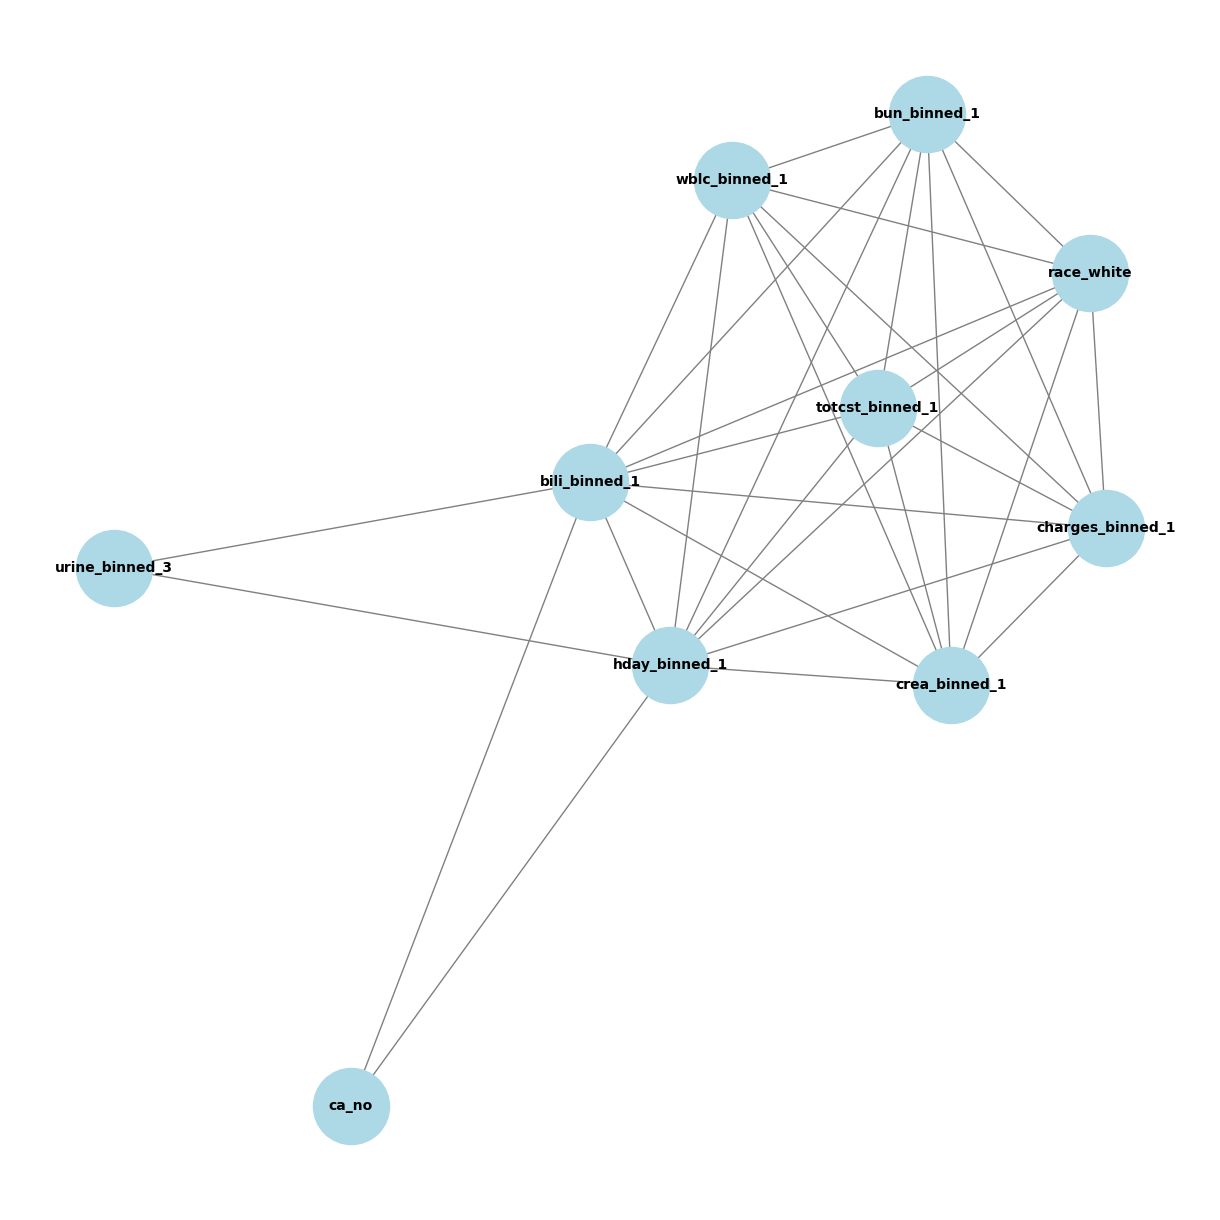

In [12]:

G = nx.Graph()

for _, row in df_reglas.iterrows():
    antecedente = row['Antecedente'].split(', ')
    consecuente = row['Consecuente'].split(', ')

    for item in antecedente + consecuente:
        G.add_node(item)

    for item_a in antecedente:
        for item_c in consecuente:
            G.add_edge(item_a, item_c, support=row['Support'], confidence=row['Confidence'], lift=row['Lift'])

plt.figure(figsize=(12, 12))


pos = nx.spring_layout(G, k=0.8, iterations=100)

nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')


Analysis of the graph generated from the association rules reveals significant patterns in the interactions between variables, highlighted by metrics such as support, confidence, and lift. The most relevant findings are presented below:

1. **Core nodes with high connectivity**:
Variables such as **`hday_binned_1`** and **`charges_binned_1`** emerge as core nodes, showing frequent and strong associations with other variables. Their prominent position suggests a key or influential role within the analyzed system.

2. **Relationships in specific subsets**:
Nodes such as **`bun_binned_1`**, **`bili_binned_1`**, **`crea_binned_1`**, and **`wblc_binned_1`** present strong connections with each other. This indicates a possible contextual relationship or an association between related indicators, probably in the medical field or within similar categories.

3. **Separate components and specialized relationships**:
Variables such as **`ca_no`** and **`urine_binned_3`** are found in peripheral positions, connected only to specific nodes. This pattern suggests that these variables have limited or specialized relationships, which could reflect particular roles or isolated behaviors in the system.

4. **Importance of `charges_binned_1` as a key node**:
The node **`charges_binned_1`** acts as a central hub by connecting to multiple variables. This could indicate that it plays a mediating role or has a significant impact on the detected associations.

### Interpretation and hypothesis formulation
Based on these patterns, the following hypotheses can be proposed for future analysis:

- **Influence of medical indicators on hospital costs**:
The strong associations between **`charges_binned_1`** and variables such as **`bun_binned_1`** and **`bili_binned_1`** suggest that clinical indicators significantly influence costs.

- **Physiological relationships between variables**:
The observed interdependence between **`bun_binned_1`**, **`bili_binned_1`**, and **`crea_binned_1`** may reflect inherent physiological connections, indicating that these variables might belong to the same underlying process.

- **Length of hospitalization as a mediator**:
The centrality of **`hday_binned_1`** suggests that this variable might mediate the effects of others, acting as a key factor in the system.

- **Specific subgroups in peripheral variables**:
Variables such as **`ca_no`** and **`urine_binned_3`** might be associated with specific subgroups of patients, reflecting unique characteristics or particular treatments.

- **Demographic differences in costs and treatments**:
The connection between **`race_white`**, costs, and clinical measures suggests possible differences in medical costs and treatments based on demographic variables.

This analysis allows for the identification of key nodes, clustered relationships, and peripheral behaviors, providing a solid foundation for future research that delves deeper into interactions and underlying factors.

---

## 🛑 ANALYSIS WITH QUALITATIVE VARIABLES

In [13]:
data_apriori_dummies_cat = pd.get_dummies(data_apriori[categorical_features.columns].drop(columns=['income','sfdm2','dzclass']))
data_apriori_dummies_cat.columns

Index(['death', 'hospdead', 'diabetes', 'dementia', 'sex_female', 'sex_male',
       'dzgroup_ARF/MOSF w/Sepsis', 'dzgroup_CHF', 'dzgroup_COPD',
       'dzgroup_Cirrhosis', 'dzgroup_Colon Cancer', 'dzgroup_Coma',
       'dzgroup_Lung Cancer', 'dzgroup_MOSF w/Malig', 'race_asian',
       'race_black', 'race_hispanic', 'race_other', 'race_white',
       'ca_metastatic', 'ca_no', 'ca_yes'],
      dtype='object')

In [14]:
# Convertir el DataFrame a formato de transacción
transactions_cat = []

# Iterar por cada fila del DataFrame
for _, row in data_apriori_dummies_cat.iterrows():
    transaction = [col for col, value in row.items() if value is True]
    transactions_cat.append(tuple(transaction))  # Convertir cada transacción a tupla

In [15]:
print("\nLista de transacciones:")
print(transactions_cat)


Lista de transacciones:
[('sex_male', 'dzgroup_Lung Cancer', 'race_other', 'ca_metastatic'), ('sex_female', 'dzgroup_Cirrhosis', 'race_white', 'ca_no'), ('sex_female', 'dzgroup_Cirrhosis', 'race_white', 'ca_no'), ('sex_female', 'dzgroup_Lung Cancer', 'race_white', 'ca_metastatic'), ('sex_female', 'dzgroup_ARF/MOSF w/Sepsis', 'race_white', 'ca_no'), ('sex_male', 'dzgroup_Coma', 'race_white', 'ca_no'), ('sex_male', 'dzgroup_CHF', 'race_white', 'ca_no'), ('sex_male', 'dzgroup_CHF', 'race_white', 'ca_no'), ('sex_female', 'dzgroup_Colon Cancer', 'race_hispanic', 'ca_metastatic'), ('sex_male', 'dzgroup_CHF', 'race_white', 'ca_no'), ('sex_male', 'dzgroup_Lung Cancer', 'race_white', 'ca_metastatic'), ('sex_female', 'dzgroup_Cirrhosis', 'race_white', 'ca_no'), ('sex_male', 'dzgroup_CHF', 'race_white', 'ca_no'), ('sex_female', 'dzgroup_ARF/MOSF w/Sepsis', 'race_white', 'ca_no'), ('sex_female', 'dzgroup_Lung Cancer', 'race_white', 'ca_metastatic'), ('sex_male', 'dzgroup_Lung Cancer', 'race_white

In [16]:
conjuntos_cat, reglas_cat = apriori(transactions_cat,
                            min_support = 0.2, #min_support = 0.2, significa que las reglas generadas deben ocurrir al menos en el 20% de las transacciones.
                            min_confidence = 0.5)

In [17]:
# Filtrando reglas con consecuente de un elemento
reglas_cat = filter(lambda regla: len(regla.rhs) == 1, reglas_cat)

In [18]:
# Asumimos que 'reglas' es el conjunto de reglas generadas por apriori
reglas_dfs = []  # Lista para almacenar los DataFrames de cada regla

for regla in reglas_cat:
    # Crear un DataFrame para cada regla
    df_regla = pd.DataFrame({
        'Antecedente': [', '.join(list(regla.lhs))],  # Antecedente
        'Consecuente': [', '.join(list(regla.rhs))],  # Consecuente
        'Support': [regla.support],                    # Soporte
        'Confidence': [regla.confidence],              # Confianza
        'Lift': [regla.lift]                           # Lift
    })

    # Añadir el DataFrame de la regla a la lista
    reglas_dfs.append(df_regla)

# Concatenar todos los DataFrames de las reglas en un solo DataFrame
df_reglas_cat = pd.concat(reglas_dfs, ignore_index=True)

In [19]:
df_reglas_cat

,Antecedente,Consecuente,Support,Confidence,Lift
0,dzgroup_ARF/MOSF w/Sepsis,ca_no,0.328868,0.851058,1.288581
1,race_white,ca_no,0.511636,0.644317,0.975557
2,ca_no,race_white,0.511636,0.774665,0.975557
3,sex_female,ca_no,0.292088,0.669181,1.013203
4,sex_male,ca_no,0.368373,0.653707,0.989773
5,ca_no,sex_male,0.368373,0.557752,0.989773
6,dzgroup_ARF/MOSF w/Sepsis,race_white,0.302418,0.782609,0.985561
7,dzgroup_ARF/MOSF w/Sepsis,sex_male,0.211602,0.547591,0.971742
8,sex_female,race_white,0.336361,0.770611,0.970452
9,sex_male,race_white,0.457714,0.812248,1.022887


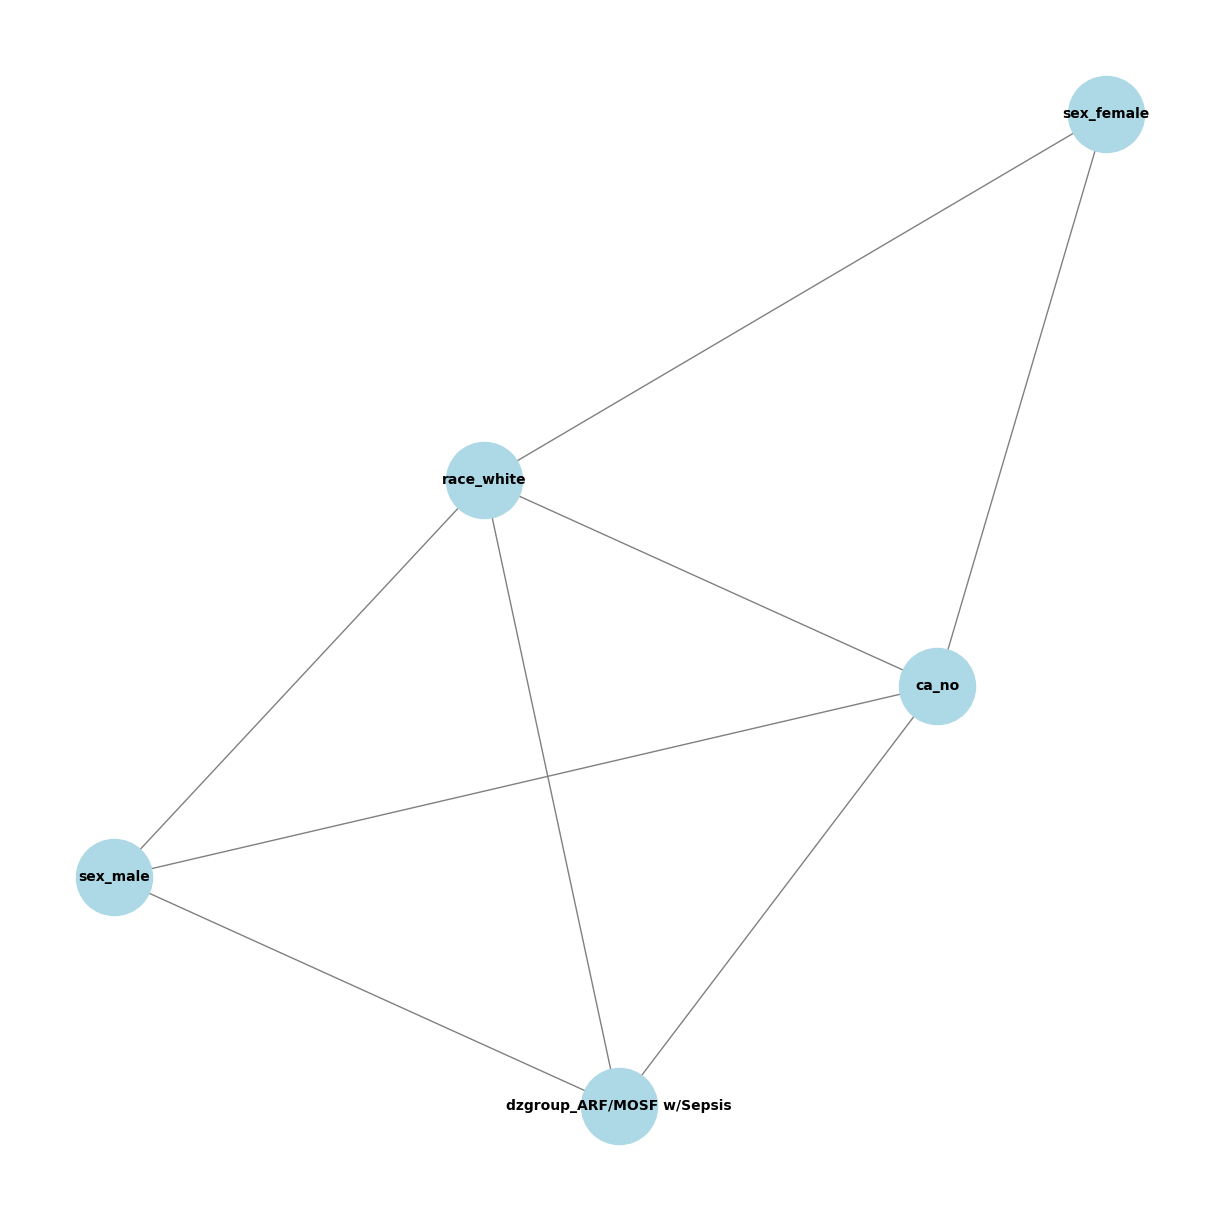

In [20]:
G = nx.Graph()

for _, row in df_reglas_cat.iterrows():
    antecedente = row['Antecedente'].split(', ')
    consecuente = row['Consecuente'].split(', ')

    for item in antecedente + consecuente:
        G.add_node(item)

    for item_a in antecedente:
        for item_c in consecuente:
            G.add_edge(item_a, item_c, support=row['Support'], confidence=row['Confidence'], lift=row['Lift'])

plt.figure(figsize=(12, 12))


pos = nx.spring_layout(G, k=0.8, iterations=100)

nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', edge_color='gray')


Association rules show interesting patterns in the data. A key observation is the strong relationship between critical illnesses such as ARF/MOSF with sepsis and the absence of cancer (`ca_no`). This rule has a support of 32.88% and a confidence of 85.11%, indicating that patients with these critical conditions have a high probability of not having cancer. Similarly, race white (`race_white`) shows a frequent relationship with the absence of cancer, with a support of 51.16% and a confidence of 64.43%.

Male sex also has a moderate association with the absence of cancer, with a support of 36.84% and a confidence of 65.37%. However, the **lift** values ​​less than 1 for these rules suggest that these associations are not particularly unusual compared to what is expected by chance.

In terms of combined characteristics, patients with ARF/MOSF and sepsis have a high probability of being white, with a confidence of 78.26%. In addition, white patients who are women are weakly associated with the absence of cancer, with a confidence of 65.54%. On the other hand, white men also have a notable relationship with the absence of cancer, although with less strength.

An interesting pattern is the combination of patients with ARF/MOSF, white race, and absence of cancer, which has a support of 25.29% and a confidence of 83.63%, with a **lift** of 1.266, indicating a notable association.

Overall, the data suggest that the absence of cancer is a common factor among several demographic and medical characteristics. However, **lift** values ​​close to 1 in most cases suggest that these associations may not be significantly unusual and could reflect demographic patterns in the sample. It should be noted that the association rules obtained may be biased because the sample used does not significantly represent the general population. In this sense, the observed values, such as support, confidence and lift, should be interpreted with caution, as they could reflect specific characteristics of the sample rather than general patterns applicable to the entire population.
What is truly relevant is not the exact values ​​of these metrics, but the model's ability to identify patterns within a sample and analyze relationships between variables. This approach allows us to understand how certain attributes, such as the diagnosis of critical illnesses, sex or race, are interrelated in a specific context. Although specific results may not be extrapolated, the model demonstrates its usefulness by finding consistent associations within the available data.
In this case, the applied methodology offers a tool to explore how different factors can interact in a population represented by the sample.